# Bagian I (Minggu 9) — Eksplorasi dan Pembersihan Data Harga Komoditas Cabai & Bawang

**Proyek:** Analisis Data Besar Harga Komoditas Cabai dan Bawang di Provinsi Lampung Menggunakan Apache Spark
**Mata Kuliah:** Mahadata IF25-40402 — Institut Teknologi Sumatera
**Kelompok 01:** Rizky Patriawan (123140112), Ahmad Mulia Saputra (123140168), Taufiqur Rahman (123140007), Ilyas Ramadhan (123140016)
**Dataset:** Tabel Harga Harian PIHPS (10 Juli 2017 – 30 Oktober 2026)

Tahap awal ini berfokus pada persiapan data mentah (*data preparation*) dan analisis data eksploratif (*Exploratory Data Analysis*). Proses mencakup pengubahan struktur tabel dari format melebar (*wide*) menjadi memanjang (*long*), penanganan nilai hilang (*imputation*), pendeteksian pencilan harga (*outlier*), serta pemetaan pola musiman dan korelasi antar-komoditas sebelum masuk ke pemrosesan terdistribusi di Apache Spark.

## 1. Setup & Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print('✅ Library berhasil diimport')

✅ Library berhasil diimport


## 2. Load & Reshape Data (Wide → Long)

In [ ]:
from google.colab import files
uploaded = files.upload()

FILE = list(uploaded.keys())[0]
df_raw = pd.read_excel(FILE, header=0)
print('Shape awal (wide):', df_raw.shape)
df_raw.head(3)

Saving Harga Cabai Bawang 10 Juli 2017 - 31 Oktober 2026.xlsx to Harga Cabai Bawang 10 Juli 2017 - 31 Oktober 2026 (1).xlsx
Shape awal (wide): (10, 2432)


,No,Komoditas (Rp),10/ 07/ 2017,11/ 07/ 2017,12/ 07/ 2017,13/ 07/ 2017,14/ 07/ 2017,17/ 07/ 2017,18/ 07/ 2017,19/ 07/ 2017,...,19/ 10/ 2026,20/ 10/ 2026,21/ 10/ 2026,22/ 10/ 2026,23/ 10/ 2026,26/ 10/ 2026,27/ 10/ 2026,28/ 10/ 2026,29/ 10/ 2026,30/ 10/ 2026
0,I,Bawang Merah,30650,31150,30900,30900,29650,29150,28150,28250,...,31250,31250,31250,31150,31400,31400,31650,31150,30900,30900
1,1,Bawang Merah Ukuran Sedang,30650,31150,30900,30900,29650,29150,28150,28250,...,31250,31250,31250,31150,31400,31400,31650,31150,30900,30900
2,II,Bawang Putih,31000,34000,33500,33150,33500,33750,33150,32500,...,35400,35400,35400,35400,35400,35400,35400,35400,35150,35150


In [ ]:
# Reshape wide → long
date_cols = df_raw.columns[2:]

df_long = df_raw.melt(
    id_vars=['No', 'Komoditas (Rp)'],
    value_vars=date_cols,
    var_name='tanggal_raw',
    value_name='harga_raw'
)

# Parse tanggal — format 'DD/ MM/ YYYY' (ada spasi)
df_long['tanggal'] = pd.to_datetime(
    df_long['tanggal_raw'].astype(str).str.replace(' ', ''),
    format='%d/%m/%Y', errors='coerce'
)

# Parse harga: '-' → NaN, hapus pemisah ribuan
df_long['harga'] = df_long['harga_raw'].replace('-', np.nan)
df_long['harga'] = df_long['harga'].astype(str).str.replace(',', '').str.strip()
df_long['harga'] = pd.to_numeric(df_long['harga'], errors='coerce')

df_long = df_long.rename(columns={'Komoditas (Rp)': 'komoditas'})
df_long = df_long[['tanggal', 'komoditas', 'harga']]
df_long = df_long.sort_values(['komoditas', 'tanggal']).reset_index(drop=True)

print('Shape setelah reshape (long):', df_long.shape)
print('Periode:', df_long['tanggal'].min().date(), 's.d.', df_long['tanggal'].max().date())
print('Komoditas:', df_long['komoditas'].nunique())
print('Hari trading unik:', df_long['tanggal'].nunique())
df_long.head(10)

Shape setelah reshape (long): (24300, 3)
Periode: 2017-07-10 s.d. 2026-10-30
Komoditas: 10
Hari trading unik: 2430


,tanggal,komoditas,harga
0,2017-07-10,Bawang Merah,30650.0
1,2017-07-11,Bawang Merah,31150.0
2,2017-07-12,Bawang Merah,30900.0
3,2017-07-13,Bawang Merah,30900.0
4,2017-07-14,Bawang Merah,29650.0
5,2017-07-17,Bawang Merah,29150.0
6,2017-07-18,Bawang Merah,28150.0
7,2017-07-19,Bawang Merah,28250.0
8,2017-07-20,Bawang Merah,28500.0
9,2017-07-21,Bawang Merah,28250.0


## 3. Gambaran Data

In [ ]:
print('=== GAMBARAN DATASET ===')
print(f'Jumlah baris  : {len(df_long):,}')
print(f'Jumlah kolom  : {df_long.shape[1]}')
print(f'Periode       : {df_long["tanggal"].min().date()} s.d. {df_long["tanggal"].max().date()}')
print(f'Hari trading  : {df_long["tanggal"].nunique()} hari')
print(f'Komoditas     : {df_long["komoditas"].nunique()} jenis')
print()
print('Daftar komoditas:')
for k in df_long['komoditas'].unique():
    print(f'  - {k}')
print()
print('Tipe variabel:')
print(df_long.dtypes)

=== GAMBARAN DATASET ===
Jumlah baris  : 24,300
Jumlah kolom  : 3
Periode       : 2017-07-10 s.d. 2026-10-30
Hari trading  : 2430 hari
Komoditas     : 10 jenis

Daftar komoditas:
  - Bawang Merah
  - Bawang Merah Ukuran Sedang
  - Bawang Putih
  - Bawang Putih Ukuran Sedang
  - Cabai Merah
  - Cabai Merah Besar
  - Cabai Merah Keriting
  - Cabai Rawit
  - Cabai Rawit Hijau
  - Cabai Rawit Merah

Tipe variabel:
tanggal      datetime64[ns]
komoditas            object
harga               float64
dtype: object


## 4. Kualitas Data

In [ ]:
print('=== CEK NILAI HILANG ===')
null_count = df_long['harga'].isna().sum()
null_pct = null_count / len(df_long) * 100
print(f'Total nilai hilang : {null_count} ({null_pct:.2f}%)')
print()
print('Nilai hilang per komoditas:')
null_per = df_long.groupby('komoditas')['harga'].apply(lambda x: x.isna().sum())
print(null_per.to_string())

=== CEK NILAI HILANG ===
Total nilai hilang : 840 (3.46%)

Nilai hilang per komoditas:
komoditas
Bawang Merah                  84
Bawang Merah Ukuran Sedang    84
Bawang Putih                  84
Bawang Putih Ukuran Sedang    84
Cabai Merah                   84
Cabai Merah Besar             84
Cabai Merah Keriting          84
Cabai Rawit                   84
Cabai Rawit Hijau             84
Cabai Rawit Merah             84


In [ ]:
print('=== CEK DUPLIKASI ===')
dup = df_long.duplicated(subset=['tanggal','komoditas']).sum()
print(f'Baris duplikat: {dup}')
print()

print('=== CEK PENCILAN (Z-SCORE > 3) ===')
df_long['zscore'] = df_long.groupby('komoditas')['harga'].transform(
    lambda x: np.abs(stats.zscore(x, nan_policy='omit'))
)
outliers = df_long[df_long['zscore'] > 3]
print(f'Total pencilan terdeteksi: {len(outliers)}')
print()
print(outliers[['tanggal','komoditas','harga']].to_string())

=== CEK DUPLIKASI ===
Baris duplikat: 0

=== CEK PENCILAN (Z-SCORE > 3) ===
Total pencilan terdeteksi: 159

         tanggal                   komoditas     harga
1300  2022-07-04                Bawang Merah   56400.0
1301  2022-07-05                Bawang Merah   56500.0
1302  2022-07-06                Bawang Merah   58150.0
1303  2022-07-07                Bawang Merah   58150.0
1304  2022-07-08                Bawang Merah   59250.0
1305  2022-07-11                Bawang Merah   59250.0
1306  2022-07-12                Bawang Merah   59250.0
1307  2022-07-13                Bawang Merah   58250.0
1308  2022-07-14                Bawang Merah   57000.0
1768  2024-04-18                Bawang Merah   56900.0
1769  2024-04-19                Bawang Merah   57900.0
1771  2024-04-23                Bawang Merah   56900.0
1772  2024-04-24                Bawang Merah   58150.0
1773  2024-04-25                Bawang Merah   57500.0
1774  2024-04-26                Bawang Merah   58150.0
2103  2025-0

In [ ]:
# Penanganan: imputasi nilai hilang dengan forward-fill
df_clean = df_long.copy()
df_clean['harga'] = df_clean.groupby('komoditas')['harga'].transform(
    lambda x: x.ffill()
)
df_clean = df_clean.drop(columns='zscore')

null_after = df_clean['harga'].isna().sum()
print(f'Nilai hilang setelah forward-fill: {null_after}')
print('✅ Data siap untuk analisis')

Nilai hilang setelah forward-fill: 0
✅ Data siap untuk analisis


## 5. Visualisasi Eksplorasi

### Viz 1 — Tren Harga Harian per Komoditas (Time Series)

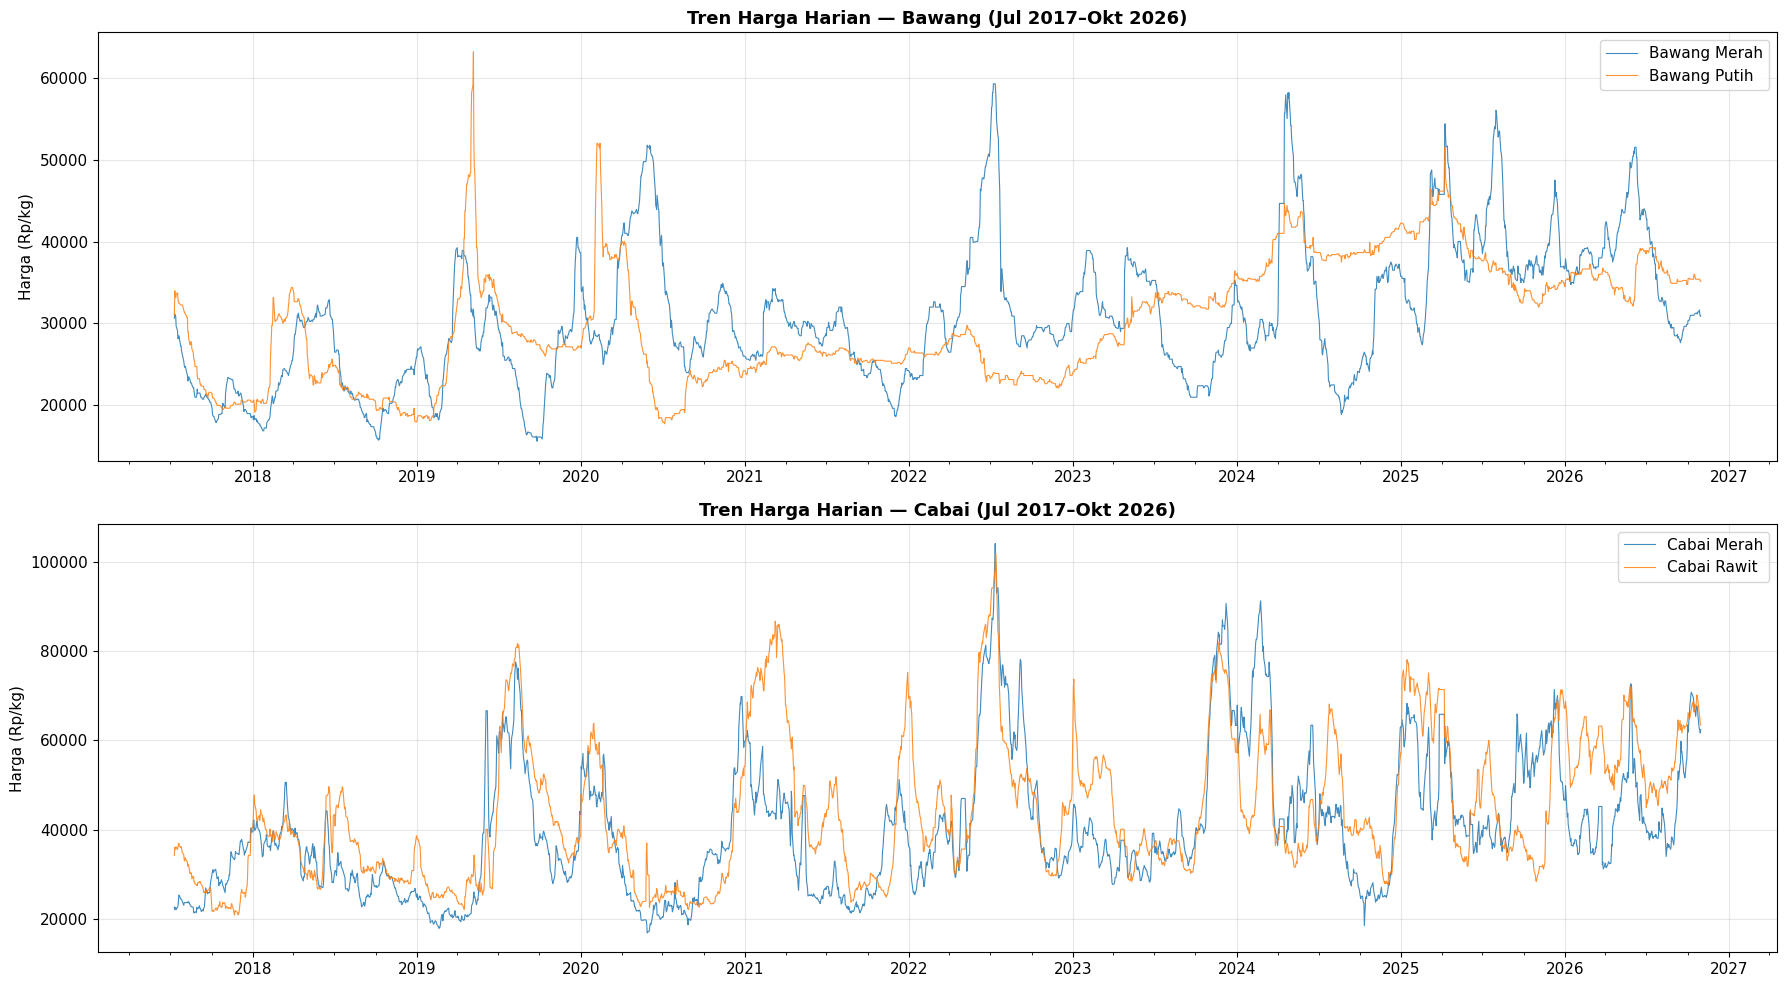

✅ viz1_tren_harga.png tersimpan


In [ ]:
bawang = ['Bawang Merah', 'Bawang Putih']
utama  = ['Bawang Merah', 'Bawang Putih', 'Cabai Merah', 'Cabai Rawit']

fig, axes = plt.subplots(2, 1, figsize=(18, 10))

for kom in bawang:
    d = df_clean[df_clean['komoditas'] == kom]
    axes[0].plot(d['tanggal'], d['harga'], label=kom, linewidth=0.8, alpha=0.85)
axes[0].set_title('Tren Harga Harian — Bawang (Jul 2017–Okt 2026)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Harga (Rp/kg)')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=0)

for kom in ['Cabai Merah', 'Cabai Rawit']:
    d = df_clean[df_clean['komoditas'] == kom]
    axes[1].plot(d['tanggal'], d['harga'], label=kom, linewidth=0.8, alpha=0.85)
axes[1].set_title('Tren Harga Harian — Cabai (Jul 2017–Okt 2026)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Harga (Rp/kg)')
axes[1].legend()
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('viz1_tren_harga.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ viz1_tren_harga.png tersimpan')

### Viz 2 — Distribusi Harga per Komoditas (Boxplot)

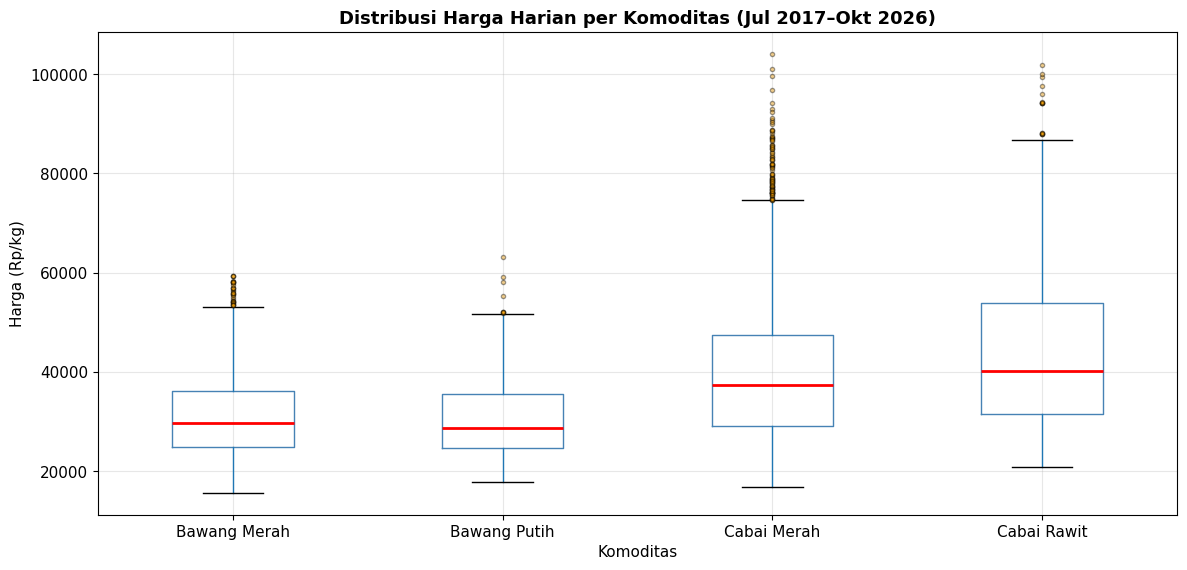

✅ viz2_distribusi_boxplot.png tersimpan


In [ ]:
df_utama = df_clean[df_clean['komoditas'].isin(utama)]

fig, ax = plt.subplots(figsize=(12, 6))
df_utama.boxplot(column='harga', by='komoditas', ax=ax,
                 boxprops=dict(color='steelblue'),
                 medianprops=dict(color='red', linewidth=2),
                 flierprops=dict(marker='o', markerfacecolor='orange', markersize=3, alpha=0.4))
ax.set_title('Distribusi Harga Harian per Komoditas (Jul 2017–Okt 2026)', fontsize=13, fontweight='bold')
ax.set_xlabel('Komoditas')
ax.set_ylabel('Harga (Rp/kg)')
plt.suptitle('')
plt.tight_layout()
plt.savefig('viz2_distribusi_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ viz2_distribusi_boxplot.png tersimpan')

### Viz 3 — Heatmap Korelasi Antar Komoditas

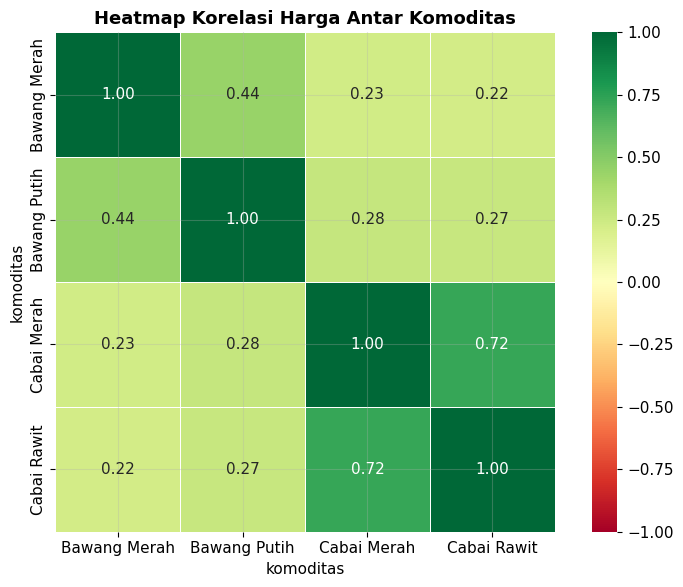

Nilai Korelasi:
komoditas     Bawang Merah  Bawang Putih  Cabai Merah  Cabai Rawit
komoditas                                                         
Bawang Merah         1.000         0.445        0.232        0.224
Bawang Putih         0.445         1.000        0.278        0.269
Cabai Merah          0.232         0.278        1.000        0.723
Cabai Rawit          0.224         0.269        0.723        1.000


In [ ]:
df_pivot = df_clean[df_clean['komoditas'].isin(utama)].pivot_table(
    index='tanggal', columns='komoditas', values='harga'
)
corr = df_pivot.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Heatmap Korelasi Harga Antar Komoditas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('viz3_heatmap_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()
print('Nilai Korelasi:')
print(corr.round(3))

### Viz 4 (Bonus) — Pola Musiman Bulanan

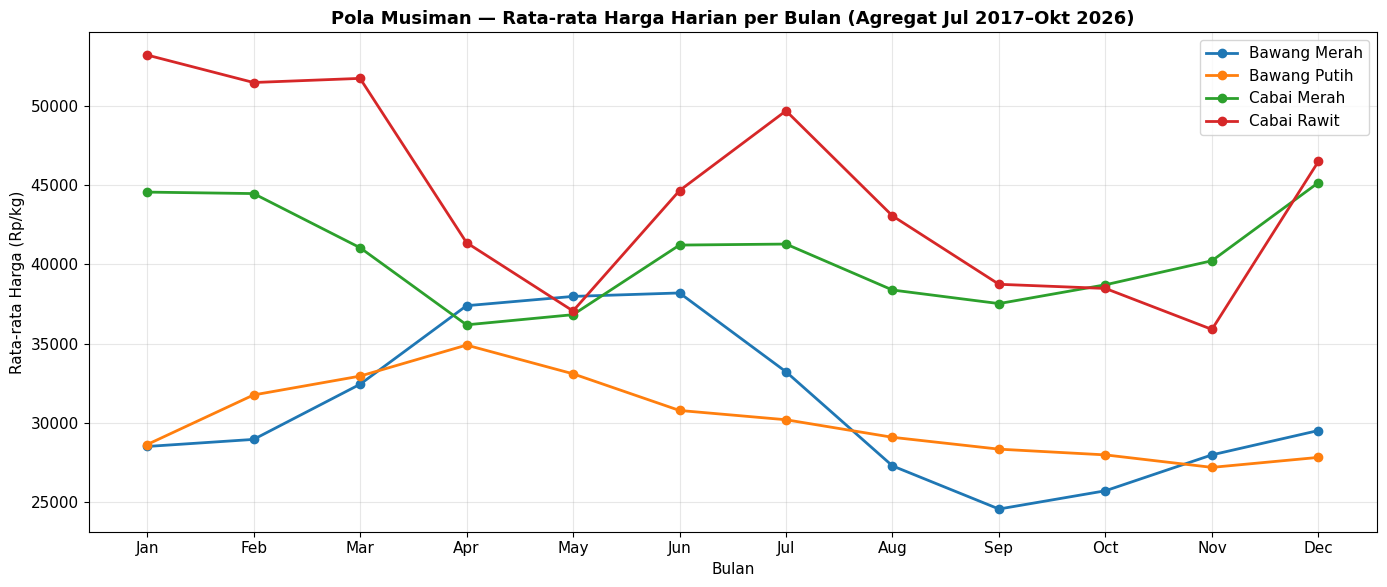

✅ viz4_pola_musiman.png tersimpan


In [ ]:
df_clean['bulan'] = df_clean['tanggal'].dt.month
df_clean['nama_bulan'] = df_clean['tanggal'].dt.strftime('%b')

musiman = df_clean[df_clean['komoditas'].isin(utama)].groupby(
    ['nama_bulan','komoditas','bulan'])['harga'].mean().reset_index()
musiman = musiman.sort_values('bulan')

fig, ax = plt.subplots(figsize=(14, 6))
for kom in utama:
    d = musiman[musiman['komoditas'] == kom]
    ax.plot(d['nama_bulan'], d['harga'], marker='o', label=kom, linewidth=2)

ax.set_title('Pola Musiman — Rata-rata Harga Harian per Bulan (Agregat Jul 2017–Okt 2026)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Bulan')
ax.set_ylabel('Rata-rata Harga (Rp/kg)')
ax.legend()
plt.tight_layout()
plt.savefig('viz4_pola_musiman.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ viz4_pola_musiman.png tersimpan')

## 6. Ringkasan Statistik Deskriptif

In [ ]:
print('=== STATISTIK DESKRIPTIF ===')
stats_sum = df_clean.groupby('komoditas')['harga'].agg(['min','max','mean','std']).round(0)
stats_sum.columns = ['Min (Rp)', 'Max (Rp)', 'Rata-rata (Rp)', 'Std Dev (Rp)']
print(stats_sum.to_string())
print()
cv = df_clean.groupby('komoditas')['harga'].apply(
    lambda x: (x.std()/x.mean())*100
).round(2)
print('Koefisien Variasi (volatilitas):')
print(cv.sort_values(ascending=False).to_string())
print()
print('→ Paling volatil:', cv.idxmax())
print('→ Paling stabil :', cv.idxmin())

=== STATISTIK DESKRIPTIF ===
                            Min (Rp)  Max (Rp)  Rata-rata (Rp)  Std Dev (Rp)
komoditas                                                                   
Bawang Merah                 15650.0   59250.0         30855.0        8317.0
Bawang Merah Ukuran Sedang   15650.0   59250.0         30855.0        8317.0
Bawang Putih                 17750.0   63150.0         30164.0        7194.0
Bawang Putih Ukuran Sedang   17750.0   63150.0         30164.0        7194.0
Cabai Merah                  16900.0  104100.0         40390.0       15190.0
Cabai Merah Besar            15000.0  107500.0         49912.0       13875.0
Cabai Merah Keriting         10650.0  105650.0         37575.0       16026.0
Cabai Rawit                  20850.0  101900.0         44228.0       15740.0
Cabai Rawit Hijau            21400.0  101900.0         42197.0       13604.0
Cabai Rawit Merah            18250.0  115650.0         46236.0       19172.0

Koefisien Variasi (volatilitas):
komoditas
Cab

---
# Bagian II (Minggu 10) — Pemodelan Prediksi Harga Komoditas dengan PySpark MLlib

Pada tahap ini, dataset hasil pembersihan dari proses EDA dimuat ke dalam lingkungan komputasi terdistribusi **Apache Spark**. Proses mencakup pembentukan fitur historis menggunakan *Window Function* berdasarkan masing-masing komoditas, pembagian data latih dan uji secara kronologis (80:20), serta pengujian komparatif terhadap model *Linear Regression*, *Random Forest*, dan *Gradient-Boosted Trees* untuk memperoleh model prediksi harga harian ($t+1$) dengan tingkat galat terendah.

In [ ]:
!pip install -q pyspark

from typing import List, Dict, Tuple
from functools import reduce
import pandas as pd

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator


class LampungCommodityPipeline:
    # Pipeline analitik data besar untuk peramalan harga komoditas hortikultura Lampung

    def __init__(self, app_name: str = "LampungHorticultureBigData_IF"):
        self.spark = (
            SparkSession.builder
            .appName(app_name)
            .config("spark.sql.shuffle.partitions", "8")
            .config("spark.driver.memory", "4g")
            .getOrCreate()
        )
        self.feature_cols = [
            "harga", "lag_1d", "lag_2d", "lag_7d", "lag_14d", "lag_30d",
            "ma_7d", "ma_30d", "volatility_30d", "roc_7d", "bulan", "hari_minggu"
        ]
        self.best_models: Dict[str, PipelineModel] = {}

    def ingest_silver_layer(self, pdf_clean: pd.DataFrame, target_commodities: List[str]) -> DataFrame:
        # Konversi data bersih ke Spark DataFrame terpartisi
        sdf = (
            self.spark.createDataFrame(pdf_clean)
            .filter(F.col("komoditas").isin(target_commodities))
            .withColumn("tanggal", F.to_date("tanggal"))
            .dropDuplicates(["komoditas", "tanggal"])
            .orderBy("komoditas", "tanggal")
        )
        return sdf

    def build_temporal_features(self, sdf: DataFrame) -> DataFrame:
        # Rekayasa fitur deret waktu dan deteksi anomali Z-Score di Spark
        w_spec = Window.partitionBy("komoditas").orderBy("tanggal")
        w_7d = w_spec.rowsBetween(-6, 0)
        w_30d = w_spec.rowsBetween(-29, 0)

        sdf_feat = (
            sdf
            .withColumn("lag_1d", F.lag("harga", 1).over(w_spec))
            .withColumn("lag_2d", F.lag("harga", 2).over(w_spec))
            .withColumn("lag_7d", F.lag("harga", 7).over(w_spec))
            .withColumn("lag_14d", F.lag("harga", 14).over(w_spec))
            .withColumn("lag_30d", F.lag("harga", 30).over(w_spec))
            .withColumn("ma_7d", F.avg("harga").over(w_7d))
            .withColumn("ma_30d", F.avg("harga").over(w_30d))
            .withColumn("volatility_30d", F.stddev("harga").over(w_30d))
            .withColumn("roc_7d", (F.col("harga") - F.col("lag_7d")) / F.col("lag_7d"))
            .withColumn(
                "z_score_30d",
                F.when(F.col("volatility_30d") > 0, (F.col("harga") - F.col("ma_30d")) / F.col("volatility_30d"))
                .otherwise(0.0)
            )
            .withColumn("is_anomaly", F.when(F.abs(F.col("z_score_30d")) > 3.0, 1).otherwise(0))
            .withColumn("bulan", F.month("tanggal"))
            .withColumn("hari_minggu", F.dayofweek("tanggal"))
            .withColumn("target_t1", F.lead("harga", 1).over(w_spec))
            .dropna()
        )
        return sdf_feat

    @staticmethod
    def _evaluate_predictions(df_pred: DataFrame) -> Dict[str, float]:
        # Hitung metrik MAE, RMSE, R2, dan MAPE secara terdistribusi
        metrics = {}
        for m_name in ["mae", "rmse", "r2"]:
            evaluator = RegressionEvaluator(labelCol="target_t1", predictionCol="prediction", metricName=m_name)
            metrics[m_name.upper()] = evaluator.evaluate(df_pred)

        mape_val = df_pred.select(
            F.avg(F.abs((F.col("target_t1") - F.col("prediction")) / F.col("target_t1"))) * 100
        ).collect()[0][0]
        metrics["MAPE"] = mape_val
        return metrics

    def train_and_select_models(self, sdf_feat: DataFrame, commodities: List[str], split_ratio: float = 0.8) -> Tuple[pd.DataFrame, DataFrame]:
        # Latih dan bandingkan 3 model regresi MLlib dengan pembagian data kronologis (80:20)
        candidates = {
            "Linear Regression (L2)": LinearRegression(featuresCol="features", labelCol="target_t1", regParam=0.5, elasticNetParam=0.0),
            "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="target_t1", numTrees=60, maxDepth=6, seed=42),
            "Gradient-Boosted Trees": GBTRegressor(featuresCol="features", labelCol="target_t1", maxIter=50, maxDepth=5, seed=42),
        }

        assembler = VectorAssembler(inputCols=self.feature_cols, outputCol="raw_features")
        scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)

        benchmark_records = []
        selected_predictions = []

        for kom in commodities:
            df_kom = sdf_feat.filter(F.col("komoditas") == kom).withColumn(
                "seq_id", F.row_number().over(Window.orderBy("tanggal"))
            )
            cutoff = int(df_kom.count() * split_ratio)

            train_sdf = df_kom.filter(F.col("seq_id") <= cutoff).cache()
            test_sdf = df_kom.filter(F.col("seq_id") > cutoff).cache()

            best_score = float("-inf")
            champion_pred = None

            for algo_name, regressor in candidates.items():
                ml_pipeline = Pipeline(stages=[assembler, scaler, regressor])
                fitted_pipe = ml_pipeline.fit(train_sdf)
                preds = fitted_pipe.transform(test_sdf)

                scores = self._evaluate_predictions(preds)
                benchmark_records.append({
                    "Komoditas": kom,
                    "Algoritma": algo_name,
                    "MAE (Rp)": round(scores["MAE"], 0),
                    "RMSE (Rp)": round(scores["RMSE"], 0),
                    "R2 Score": round(scores["R2"], 4),
                    "MAPE (%)": round(scores["MAPE"], 2)
                })

                if scores["R2"] > best_score:
                    best_score = scores["R2"]
                    self.best_models[kom] = fitted_pipe
                    champion_pred = preds.withColumn("champion_model", F.lit(algo_name))
                    artifact_path = f"artifacts/spark_model_{kom.lower().replace(' ', '_')}"
                    fitted_pipe.write().overwrite().save(artifact_path)

            selected_predictions.append(champion_pred)
            train_sdf.unpersist()
            test_sdf.unpersist()

        df_benchmark = pd.DataFrame(benchmark_records)
        sdf_champion_all = reduce(DataFrame.unionAll, selected_predictions)
        return df_benchmark, sdf_champion_all


# --- Eksekusi Pemodelan Minggu 10 ---
KOMODITAS_TARGET = ["Bawang Merah", "Bawang Putih", "Cabai Merah", "Cabai Rawit"]

pipeline_engine = LampungCommodityPipeline()
sdf_silver = pipeline_engine.ingest_silver_layer(df_clean, KOMODITAS_TARGET)
sdf_features = pipeline_engine.build_temporal_features(sdf_silver)

df_hasil_benchmark, sdf_prediksi_terbaik = pipeline_engine.train_and_select_models(
    sdf_features, KOMODITAS_TARGET, split_ratio=0.8
)

print("=== BENCHMARK EVALUASI MODEL SPARK MLlib (DATA UJI 20%) ===")
display(df_hasil_benchmark)

=== BENCHMARK EVALUASI MODEL SPARK MLlib (DATA UJI 20%) ===


,Komoditas,Algoritma,MAE (Rp),RMSE (Rp),R2 Score,MAPE (%)
0,Bawang Merah,Linear Regression (L2),581.0,943.0,0.9765,1.45
1,Bawang Merah,Random Forest,924.0,1364.0,0.9509,2.27
2,Bawang Merah,Gradient-Boosted Trees,1178.0,1656.0,0.9277,2.89
3,Bawang Putih,Linear Regression (L2),274.0,532.0,0.9789,0.72
4,Bawang Putih,Random Forest,792.0,1219.0,0.8891,2.03
5,Bawang Putih,Gradient-Boosted Trees,843.0,1342.0,0.8656,2.14
6,Cabai Merah,Linear Regression (L2),1626.0,2638.0,0.9398,3.35
7,Cabai Merah,Random Forest,2097.0,3228.0,0.9099,4.21
8,Cabai Merah,Gradient-Boosted Trees,2226.0,3387.0,0.9008,4.46
9,Cabai Rawit,Linear Regression (L2),1307.0,1931.0,0.9768,2.45


---
# Bagian III (Minggu 11) — Sistem Pendukung Keputusan dan Dasbor Pemantauan Harga

Tahap akhir ini mengonversi keluaran prediksi harga harian ($t+1$) dari model terbaik Spark MLlib menjadi indikator status siaga dan rekomendasi tindakan bagi Dinas Ketahanan Pangan/TPID, petani, serta pedagang. Seluruh aturan keputusan diproses secara terdistribusi di Apache Spark, disimpan dalam format **Apache Parquet**, dan disajikan melalui dasbor interaktif.

=== 1. RINGKASAN KEPUTUSAN PEMANGKU KEPENTINGAN (DATA TERKINI) ===


,Tanggal_Data,Komoditas,Model_Terpilih,Harga_Aktual_Rp,Prediksi_Besok_Rp,Perubahan_Pct,Status_Peringatan,Rekomendasi_Tindakan
0,2026-10-29,Bawang Merah,Linear Regression (L2),30900.0,30824.0,-0.25,HIJAU (STABIL),Seluruh Pemangku Kepentingan: Kondisi pasar ko...
1,2026-10-29,Bawang Putih,Linear Regression (L2),35150.0,35090.0,-0.17,HIJAU (STABIL),Seluruh Pemangku Kepentingan: Kondisi pasar ko...
2,2026-10-29,Cabai Merah,Linear Regression (L2),61650.0,61251.0,-0.65,HIJAU (STABIL),Seluruh Pemangku Kepentingan: Kondisi pasar ko...
3,2026-10-29,Cabai Rawit,Linear Regression (L2),63800.0,62945.0,-1.34,HIJAU (STABIL),Seluruh Pemangku Kepentingan: Kondisi pasar ko...



=== 2. VERIFIKASI INFRASTRUKTUR SPARK & DATA LAKEHOUSE (PARQUET) ===
Versi Spark           : 4.0.5
Jumlah Partisi RDD    : 4 partisi
Total Baris Parquet   : 1,920 baris
+------------+--------------------+-----+
|   komoditas|         level_siaga|count|
+------------+--------------------+-----+
|Bawang Merah|BIRU (SURPLUS PANEN)|  125|
|Bawang Merah|      HIJAU (STABIL)|  208|
|Bawang Merah|    KUNING (WASPADA)|  107|
|Bawang Merah|MERAH (SIAGA TINGGI)|   40|
|Bawang Putih|      HIJAU (STABIL)|  447|
|Bawang Putih|    KUNING (WASPADA)|   27|
|Bawang Putih|MERAH (SIAGA TINGGI)|    6|
| Cabai Merah|BIRU (SURPLUS PANEN)|  126|
| Cabai Merah|      HIJAU (STABIL)|  154|
| Cabai Merah|    KUNING (WASPADA)|   96|
| Cabai Merah|MERAH (SIAGA TINGGI)|  104|
| Cabai Rawit|BIRU (SURPLUS PANEN)|  129|
| Cabai Rawit|      HIJAU (STABIL)|  173|
| Cabai Rawit|    KUNING (WASPADA)|   74|
| Cabai Rawit|MERAH (SIAGA TINGGI)|  104|
+------------+--------------------+-----+



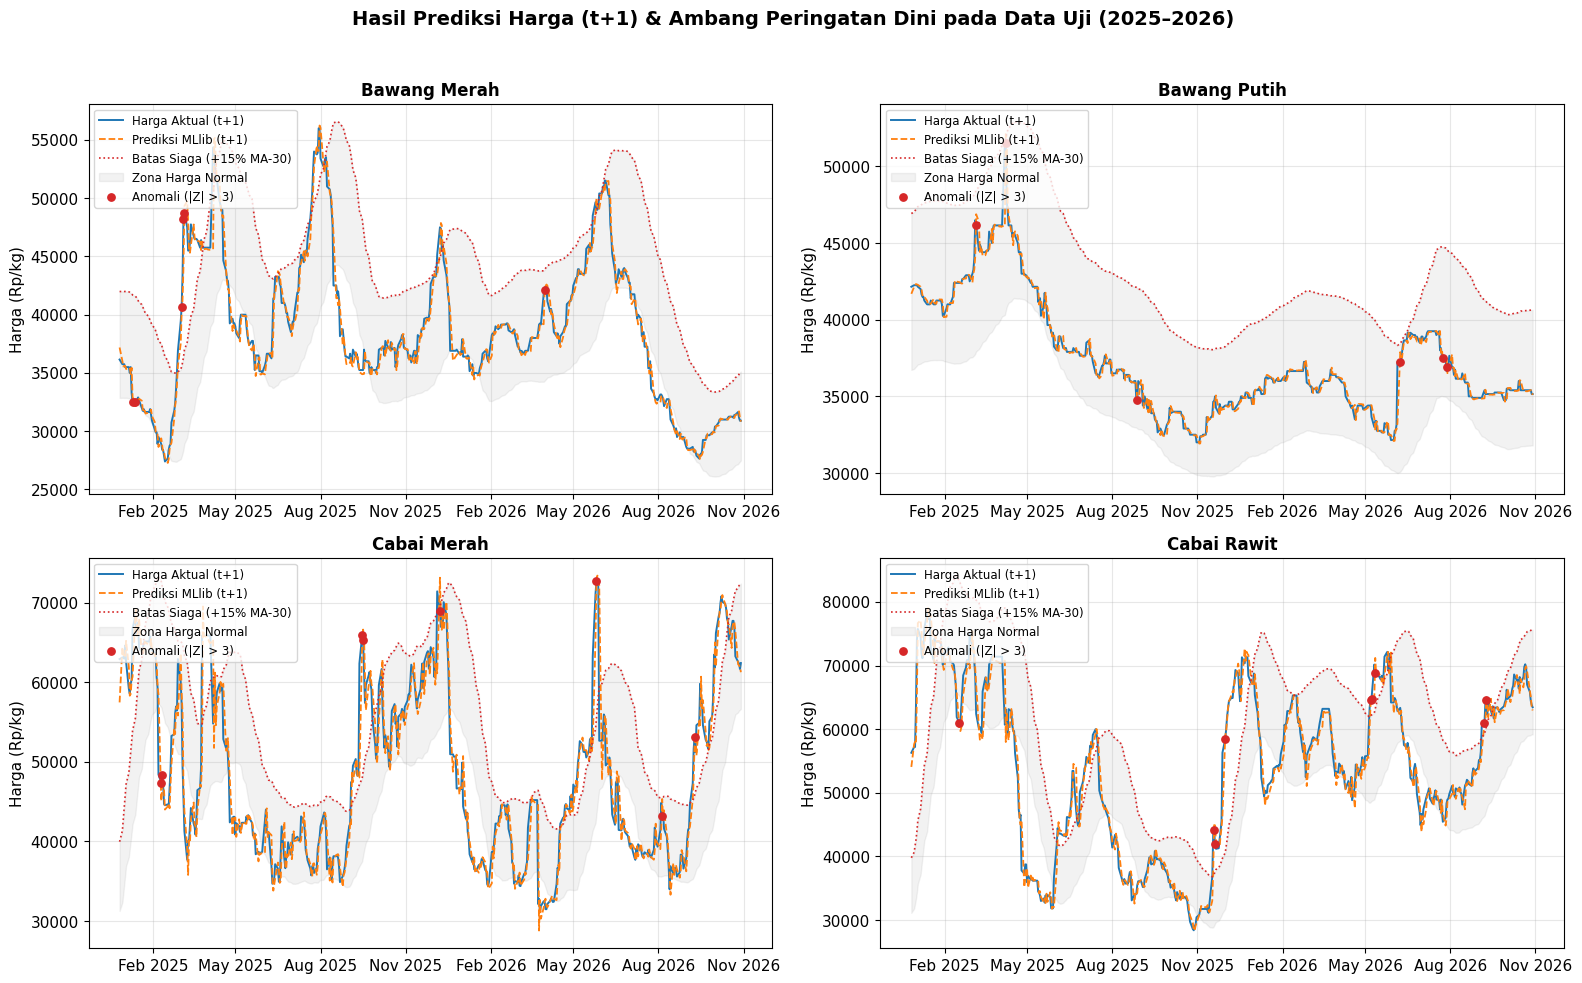

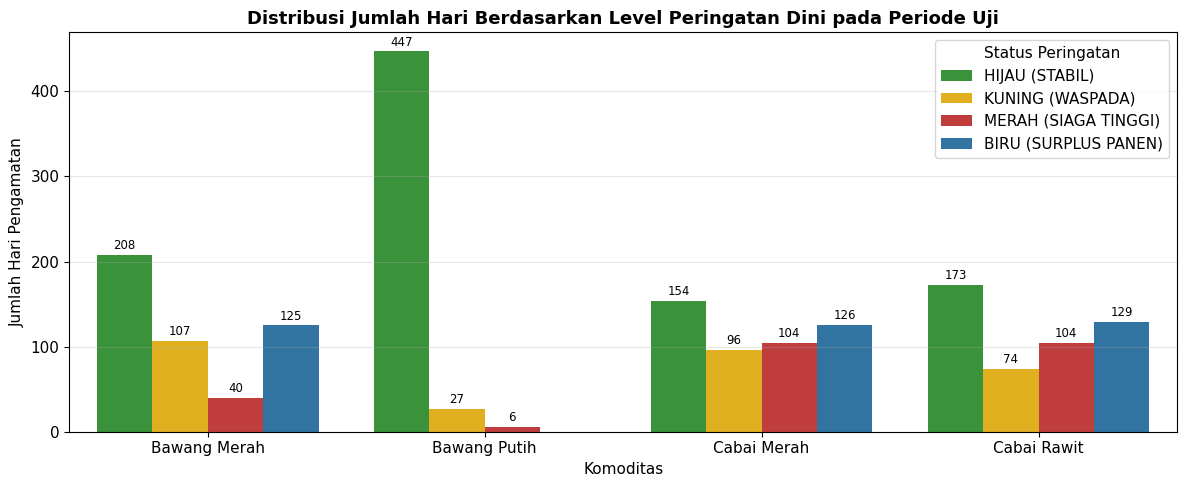

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns


def generate_decision_layer(sdf_preds: DataFrame) -> DataFrame:
    # Hitung persentase perubahan harga besok (t+1), deviasi terhadap MA-30, dan aturan keputusan
    sdf_out = (
        sdf_preds
        .withColumn("delta_t1_pct", F.round(((F.col("prediction") - F.col("harga")) / F.col("harga")) * 100, 2))
        .withColumn("deviasi_ma30_pct", F.round(((F.col("prediction") - F.col("ma_30d")) / F.col("ma_30d")) * 100, 2))
        .withColumn(
            "level_siaga",
            F.when((F.col("deviasi_ma30_pct") > 15.0) | (F.col("delta_t1_pct") > 5.0) | (F.col("is_anomaly") == 1), "MERAH (SIAGA TINGGI)")
             .when((F.col("deviasi_ma30_pct") > 5.0) | (F.col("delta_t1_pct") > 1.5), "KUNING (WASPADA)")
             .when(F.col("deviasi_ma30_pct") < -10.0, "BIRU (SURPLUS PANEN)")
             .otherwise("HIJAU (STABIL)")
        )
        .withColumn(
            "rekomendasi_kebijakan",
            F.when(F.col("level_siaga") == "MERAH (SIAGA TINGGI)", "TPID/Dinas: Intervensi operasi pasar murah & distribusi pasokan antar-daerah.")
             .when(F.col("level_siaga") == "KUNING (WASPADA)", "Distributor/Dinas: Pengawasan ketat stok gudang & kelancaran rantai pasok.")
             .when(F.col("level_siaga") == "BIRU (SURPLUS PANEN)", "Petani/Bulog: Penyerapan hasil panen lokal & penyimpanan stok penyangga.")
             .otherwise("Seluruh Pemangku Kepentingan: Kondisi pasar kondusif, distribusi normal.")
        )
    )
    return sdf_out


# 1. Jalankan aturan keputusan di Spark & simpan ke format Big Data (Apache Parquet)
sdf_decisions = generate_decision_layer(sdf_prediksi_terbaik)
sdf_decisions.write.mode("overwrite").parquet("output_bigdata/lampung_commodity_decisions.parquet")

# 2. Ambil ringkasan keputusan pada tanggal terakhir per komoditas
w_latest = Window.partitionBy("komoditas").orderBy(F.col("tanggal").desc())
sdf_summary_latest = (
    sdf_decisions
    .withColumn("rn", F.row_number().over(w_latest))
    .filter(F.col("rn") == 1)
    .select(
        F.col("tanggal").alias("Tanggal_Data"),
        F.col("komoditas").alias("Komoditas"),
        F.col("champion_model").alias("Model_Terpilih"),
        F.round("harga", 0).alias("Harga_Aktual_Rp"),
        F.round("prediction", 0).alias("Prediksi_Besok_Rp"),
        F.col("delta_t1_pct").alias("Perubahan_Pct"),
        F.col("level_siaga").alias("Status_Peringatan"),
        F.col("rekomendasi_kebijakan").alias("Rekomendasi_Tindakan")
    )
)

pdf_brief = sdf_summary_latest.toPandas()
pdf_brief.to_csv("output_bigdata/ringkasan_keputusan_terkini.csv", index=False)

print("=== 1. RINGKASAN KEPUTUSAN PEMANGKU KEPENTINGAN (DATA TERKINI) ===")
display(pdf_brief)

# 3. Verifikasi eksekusi terdistribusi Spark & pembacaan kembali dataset Parquet
print("\n=== 2. VERIFIKASI INFRASTRUKTUR SPARK & DATA LAKEHOUSE (PARQUET) ===")
df_parquet_check = pipeline_engine.spark.read.parquet("output_bigdata/lampung_commodity_decisions.parquet")
print(f"Versi Spark           : {pipeline_engine.spark.version}")
print(f"Jumlah Partisi RDD    : {sdf_decisions.rdd.getNumPartitions()} partisi")
print(f"Total Baris Parquet   : {df_parquet_check.count():,} baris")
df_parquet_check.groupBy("komoditas", "level_siaga").count().orderBy("komoditas", "level_siaga").show()

# 4. Persiapan data visualisasi akhir (selaras dengan gaya plot Minggu 9)
pdf_vis = (
    sdf_decisions
    .select("tanggal", "komoditas", "target_t1", "prediction", "ma_30d", "is_anomaly", "level_siaga")
    .orderBy("tanggal")
    .toPandas()
)
pdf_vis["tanggal"] = pd.to_datetime(pdf_vis["tanggal"])

# Gambar 1: Perbandingan Aktual vs Prediksi MLlib (t+1) + Batas Ambang Siaga per Komoditas
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Hasil Prediksi Harga (t+1) & Ambang Peringatan Dini pada Data Uji (2025–2026)", fontsize=14, fontweight="bold")

for ax, kom in zip(axes.flatten(), KOMODITAS_TARGET):
    sub = pdf_vis[pdf_vis["komoditas"] == kom]
    anom = sub[sub["is_anomaly"] == 1]

    ax.plot(sub["tanggal"], sub["target_t1"], label="Harga Aktual (t+1)", color="#1f77b4", linewidth=1.4)
    ax.plot(sub["tanggal"], sub["prediction"], label="Prediksi MLlib (t+1)", color="#ff7f0e", linestyle="--", linewidth=1.3)
    ax.plot(sub["tanggal"], sub["ma_30d"] * 1.15, label="Batas Siaga (+15% MA-30)", color="#d62728", linestyle=":", linewidth=1.2)
    ax.fill_between(sub["tanggal"], sub["ma_30d"] * 0.90, sub["ma_30d"] * 1.15, color="gray", alpha=0.10, label="Zona Harga Normal")

    if len(anom) > 0:
        ax.scatter(anom["tanggal"], anom["target_t1"], color="#d62728", s=28, zorder=5, label="Anomali (|Z| > 3)")

    ax.set_title(kom, fontsize=12, fontweight="bold")
    ax.set_ylabel("Harga (Rp/kg)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.legend(loc="upper left", fontsize=8.5, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("output_bigdata/dasbor_prediksi_siaga_mg11.png", dpi=150, bbox_inches="tight")
plt.show()

# Gambar 2: Distribusi Hari Berdasarkan Status Peringatan Dini per Komoditas
status_order = ["HIJAU (STABIL)", "KUNING (WASPADA)", "MERAH (SIAGA TINGGI)", "BIRU (SURPLUS PANEN)"]
palette_status = {
    "HIJAU (STABIL)": "#2ca02c",
    "KUNING (WASPADA)": "#ffbf00",
    "MERAH (SIAGA TINGGI)": "#d62728",
    "BIRU (SURPLUS PANEN)": "#1f77b4"
}

df_status_plot = (
    pdf_vis.groupby(["komoditas", "level_siaga"])
    .size()
    .reset_index(name="jumlah_hari")
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=df_status_plot, x="komoditas", y="jumlah_hari",
    hue="level_siaga", hue_order=status_order, palette=palette_status, ax=ax
)
ax.set_title("Distribusi Jumlah Hari Berdasarkan Level Peringatan Dini pada Periode Uji", fontsize=13, fontweight="bold")
ax.set_xlabel("Komoditas")
ax.set_ylabel("Jumlah Hari Pengamatan")
ax.legend(title="Status Peringatan", frameon=True)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=8.5, padding=2)

plt.tight_layout()
plt.savefig("output_bigdata/distribusi_status_siaga_mg11.png", dpi=150, bbox_inches="tight")
plt.show()